# 3. Why MYC + BCL6 Differs from MYC + BCL2 (Norris *et al.* Figure 2C)

## Clinical Context: The WHO 2022 Double-Hit Reclassification

For years, under the **WHO 2016** lymphoma classification, aggressive B-cell lymphomas carrying a *MYC* rearrangement together with **either** a *BCL2* rearrangement **or** a *BCL6* rearrangement were grouped together under the same high-risk "Double-Hit Lymphoma" label.

However, large clinical cohorts revealed a striking difference:
- Patients with **MYC + BCL2** rearrangements consistently had dismal outcomes on standard R-CHOP chemotherapy.
- Patients with **MYC + BCL6** rearrangements (without *BCL2*) often had **significantly better prognosis** and a distinct gene-expression profile.
- Based on this clinical evidence, the **WHO 2022 (5th edition)** classification formally separated **"Diffuse large B-cell lymphoma / High-grade B-cell lymphoma with *MYC* and *BCL2* rearrangements"** from *MYC* + *BCL6* cases.

Can our **193-species multiscale model** explain *why* **MYC + BCL6** behaves so differently from **MYC + BCL2**? Let's test it directly and recreate **Figure 2C** of *Norris et al.* (*Blood Cancer Journal*, 2024)!

---

## Step 1: Load the Multiscale Model & Run the MYC + BCL6 Comparison

In our model, *BCL6* overexpression is represented by increasing its synthesis rate inside the **Differentiation** module: `"k1_s_Bcl6-differentiation" => 5.0`.

Run the two setup cells below, then simulate `WT`, `MYC × 5`, `BCL6 × 5`, and `MYC + BCL6 × 5` on the exact same `N = 20` founder cells (`seed = 123`) used in Chapter 2.

In [1]:
using DifferentialEquations
using Plots
using CSV
using DataFrames
using Random
using Statistics
using Base.Threads

gr()

function build_multiscale_model(base_dir::AbstractString="multiscale")
    modules = ["NFkB", "cellCycle", "apoptosis", "differentiation"]
    mod_dir = joinpath(base_dir, "moduleDefinitionFiles")
    comb_dir = "combinedMultiscale"
    mkpath(comb_dir)

    link_rxn = CSV.read(joinpath(mod_dir, "linking", "reactions.csv"), DataFrame; stringtype=String, types=String)
    link_par = CSV.read(joinpath(mod_dir, "linking", "parameters.csv"), DataFrame; stringtype=String, types=String)
    link_rl  = CSV.read(joinpath(mod_dir, "linking", "rateLaws.csv"), DataFrame; stringtype=String, types=String)
    replace!(link_rxn.Substrate, missing => "")
    replace!(link_rxn.Products,  missing => "")

    link_par[:, 1] = link_par[:, 1] .* "-linking"
    link_rxn.Parameters = [ismissing(p) ? missing : join([x * "-linking" for x in split(p, " ")], " ") for p in link_rxn.Parameters]

    rxn_all = copy(link_rxn)
    par_all = copy(link_par)
    rl_all  = copy(link_rl)

    for m in modules
        r_df = CSV.read(joinpath(mod_dir, m, "reactions.csv"), DataFrame; stringtype=String, types=String)
        p_df = CSV.read(joinpath(mod_dir, m, "parameters.csv"), DataFrame; stringtype=String, types=String)
        l_df = CSV.read(joinpath(mod_dir, m, "rateLaws.csv"), DataFrame; stringtype=String, types=String)
        replace!(r_df.Substrate, missing => "")
        replace!(r_df.Products,  missing => "")

        drop_r = [i for (i, row) in enumerate(eachrow(r_df))
                  if any((link_rxn.Substrate .== row.Substrate) .& (link_rxn.Products .== row.Products))]
        delete!(r_df, drop_r)
        r_df.Parameters = [ismissing(p) ? missing : join([x * "-" * m for x in split(p, " ")], " ") for p in r_df.Parameters]
        append!(rxn_all, r_df)

        drop_p = [i for (i, row) in enumerate(eachrow(p_df))
                  if any(link_par.parameter .== row.parameter) || occursin("p[", row.value)]
        delete!(p_df, drop_p)
        p_df.parameter = p_df.parameter .* ("-" * m)
        append!(par_all, p_df)
        append!(rl_all, l_df)
    end

    CSV.write(joinpath(comb_dir, "reactions.csv"),  rxn_all)
    CSV.write(joinpath(comb_dir, "parameters.csv"), par_all)
    CSV.write(joinpath(comb_dir, "rateLaws.csv"),   rl_all)

    run(`python3 $(joinpath(base_dir, "csv2model-multiscale.py")) $(joinpath(comb_dir, "reactions.csv")) $(joinpath(comb_dir, "parameters.csv")) $(joinpath(comb_dir, "rateLaws.csv")) odeMultiscaleModel.jl param`)
    return comb_dir
end

comb_dir = build_multiscale_model("multiscale")
include("variableNames.jl")
tdfunc = t -> 0.0
include("scanIncludes.jl")
include("multiscale/fixSpecies.jl")

idx(name) = findfirst(==(name), syms)
const idx_Rb      = idx("Rb")
const idx_E2FRb   = idx("E2F_Rb")
const idx_pE2FRb  = idx("pE2F_Rb")
const idx_HypoPRb = idx("HypoP_Rb")
const idx_r31Sw   = idx("r31switch")
const idx_Cdh1    = idx("Cdh1")
const idx_FateSw  = idx("fateSwitch")
const idx_CPARP   = idx("CPARP")
const idx_Mass    = idx("Mass")
const idx_GM      = idx("GM")
const idx_IRF4    = idx("IRF4")
const idx_AID     = idx("AID")
const idx_Blimp1  = idx("Blimp1")
const idx_Pax5    = idx("Pax5")
const idx_Bcl6    = idx("Bcl6")
const idx_Bcl2t   = idx("Bcl2t")
const idx_Ligand  = idx("L")

# Clamp death ligand L in both phases, and Bcl2t + differentiation markers during pre-simulation
fixSpecies("odeMultiscaleModel.jl",   "odeMultiscaleTC.jl", idx_Ligand)
fixSpecies("odeMultiscaleTC.jl",      "odeMultiscaleSS.jl", idx_Bcl2t)
for s_i in (idx_IRF4, idx_AID, idx_Blimp1, idx_Bcl6, idx_Pax5)
    fixSpecies("odeMultiscaleSS.jl",  "odeMultiscaleSS.jl", s_i)
end

# Dynamic IKK input curve (piecewise linear interpolation, as in Tutorial 3)
const totalIKK = 280.0
const basalIKK = totalIKK / 100.0
const IKKParamTime = Float64[0, 15, 30, 45, 60, 90, 120, 240, 360, 600, 1440, 2880, 4320, 5760, 7200, 8640, 14400]
const IKKParamVals = Float64[1, 1, 2, 7, 13, 19, 32, 29, 27, 20, 10, 1, 0, 0, 0, 0, 0] ./ 100.0

function ikkTC(t::Float64)::Float64
    t <= IKKParamTime[1] && return IKKParamVals[1] * totalIKK
    t >= IKKParamTime[end] && return IKKParamVals[end] * totalIKK
    @inbounds for i in 1:(length(IKKParamTime) - 1)
        if t <= IKKParamTime[i + 1]
            frac = (t - IKKParamTime[i]) / (IKKParamTime[i + 1] - IKKParamTime[i])
            return max(IKKParamVals[i] + frac * (IKKParamVals[i + 1] - IKKParamVals[i]), 0.0) * totalIKK
        end
    end
    return 0.0
end
ikkSS(t::Float64)::Float64 = basalIKK

# Specialise the 4 time-dependent parameter entries so `p` is a fast, concrete Vector{Float64}
const td_indices = [i for (i, v) in enumerate(paramVals) if !(v isa Real)]
for (src, dst, fn_name, ikk_name) in [
    ("odeMultiscaleSS.jl", "odeSS_typed.jl", "odeSS_typed!", "ikkSS"),
    ("odeMultiscaleTC.jl", "odeTC_typed.jl", "odeTC_typed!", "ikkTC"),
]
    code_str = read(src, String)
    code_str = replace(code_str, "function odeMultiscaleModel!" => "function $fn_name")
    for ti in td_indices
        code_str = replace(code_str, "p[$ti](t)" => "$(ikk_name)(t)")
    end
    code_str = replace(code_str, r"maximum\(\[([^,\]]+),0\]\)" => s"max(\1, 0.0)")
    write(dst, code_str)
end

include("odeSS_typed.jl")
include("odeTC_typed.jl")

const base_p = Float64[v isa Real ? Float64(v) : 0.0 for v in paramVals]
const idx_NIKdeg = findfirst(==("k1_NIKConstDeg-NFkB"), parameterNameList)

const base_y0 = zeros(Float64, length(syms))
for row in eachrow(CSV.read("multiscale/initialConditions/fullModelInits.csv", DataFrame; header=false))
    i = idx(String(row[1]))
    !isnothing(i) && (base_y0[i] = Float64(row[2]))
end

const p_meta = CSV.read(joinpath(comb_dir, "parameters.csv"), DataFrame;
                        types=Dict(:parameter => String, :value => String, :distribute => Int))
const dist_mask = Bool[p_meta.distribute[findfirst(==(nm), p_meta.parameter)] == 1 for nm in parameterNameList]

println("Multiscale model ready: ", length(syms), " species, ", length(base_p),
        " parameters (", count(dist_mask), " heterogeneous), ", nthreads(), " CPU thread(s).")

param
Running CSV2JuliaDiffEq with parameters dynamically determined by a variable, re-run with the 5th argument set to 'scan' or 'inline'
Opening combinedMultiscale/rateLaws.csv as rate law file
Opening combinedMultiscale/parameters.csv as parameters file
Opening combinedMultiscale/reactions.csv as reactions file


parameters can now be searched in parameterNameList by name.
example to modify k_binding 1.5 fold higher:
indexOfParam=findfirst(x->"k_binding"==x,parameterNameList)
paramVals[indexOfParam]=paramVals[indexOfParam]*1.5


Multiscale model ready: 193 species, 563 parameters (105 heterogeneous), 2 CPU thread(s).


In [2]:
# 1. RB restriction-point switch (same logic as Tutorial 5 Chapter 2)
function cond_rb(u, t, integrator)
    num = u[idx_Rb] + u[idx_E2FRb] + u[idx_pE2FRb]
    den = num + u[idx_HypoPRb]
    return (num / max(den, 1e-12)) - 0.8
end
aff_rb_pos!(integ) = (integ.u[idx_r31Sw] = 0.0)
aff_rb_neg!(integ) = (integ.u[idx_r31Sw] = 1.0)

# 2. Mitotic division callback (time course): terminates cell and marks fate = 1
cond_cdh(u, t, integrator) = u[idx_Cdh1] - 0.2
function aff_cdh_div!(integ)
    if integ.u[idx_Mass] >= 1.0
        integ.uprev[idx_FateSw] = 1.0
        integ.u[idx_FateSw]     = 1.0
        terminate!(integ)
    end
end

# 3. Apoptosis callback: terminates cell when Cleaved PARP crosses 2500 (fate = 2)
cond_cparp(u, t, integrator) = u[idx_CPARP] - 2500.0
function aff_cparp!(integ)
    integ.uprev[idx_FateSw] = 2.0
    integ.u[idx_FateSw]     = 2.0
    terminate!(integ)
end

# 4. Pre-simulation division callback: halves Mass/GM in place without spawning daughters
function aff_cdh_ss!(integ)
    integ.u[idx_Mass] *= 0.5
    integ.u[idx_GM]   *= 0.5
    integ.u[idx_r31Sw] = 1.0
    integ.u[idx_Bcl2t] = 277.0
    integ.u[idx_Cdh1]  = 1.0
end

const cb_rb     = ContinuousCallback(cond_rb, aff_rb_pos!, aff_rb_neg!)
const cb_div    = ContinuousCallback(cond_cdh, aff_cdh_div!, nothing)
const cb_death  = ContinuousCallback(cond_cparp, aff_cparp!, nothing)
const cb_ss_div = ContinuousCallback(cond_cdh, aff_cdh_ss!, nothing)

const cbs_tc    = CallbackSet(cb_rb, cb_div, cb_death)
const cbs_nodiv = CallbackSet(cb_rb, cb_death)
const cbs_ss    = CallbackSet(cb_rb, cb_ss_div)

const f_ss = ODEFunction(odeSS_typed!)
const f_tc = ODEFunction(odeTC_typed!)
const ms_alg = Rodas5P(autodiff=AutoFiniteDiff())

function rand_trunc_normal(rng, mean_val::Float64, cv::Float64)
    while true
        x = mean_val + cv * randn(rng)
        x > 0.0 && return x
    end
end

function run_one_lineage(mods::Dict{String, Float64}, rand_vec::Vector{Float64};
                         maxGens::Int=8, maxTimeTC::Float64=7200.0, preSimTime::Float64=1440.0)
    p = copy(base_p)
    for (k, v) in mods
        i = findfirst(==(k), parameterNameList)
        isnothing(i) && error("Parameter '$k' not found in parameterNameList")
        p[i] *= v
    end
    for i in eachindex(p)
        dist_mask[i] && (p[i] *= rand_vec[i])
    end

    # Phase 1: 24-hour resting steady state (L = 0, basal IKK)
    y0 = copy(base_y0)
    y0[idx_Bcl2t]  = 277.0
    y0[idx_Ligand] = 0.0
    sol_ss = solve(ODEProblem(f_ss, y0, (0.0, preSimTime), p), ms_alg;
                   callback=cbs_ss, abstol=1e-5, reltol=1e-3, save_everystep=false)

    u_cur = copy(sol_ss.u[end])
    u_cur[idx_Cdh1]   = 1.0
    u_cur[idx_IRF4]   = 0.0
    u_cur[idx_AID]    = 0.0
    u_cur[idx_Blimp1] = 0.0
    u_cur[idx_Pax5]   = 1.0
    u_cur[idx_Bcl6]   = 0.0
    u_cur[idx_Ligand] = 1.0
    p[idx_NIKdeg]    /= 10.0   # stabilise NIK at stimulation onset

    # Phase 2: simulate representative cell across generations (divCV = 0 => 2^(g-1) cells in gen g)
    fate_times = zeros(Float64, maxGens)
    t_birth = 1.0
    final_gen = 1
    for gen in 1:maxGens
        cb = gen < maxGens ? cbs_tc : cbs_nodiv
        sol = solve(ODEProblem(f_tc, u_cur, (t_birth, maxTimeTC), p), ms_alg;
                    callback=cb, abstol=1e-5, reltol=1e-3, save_everystep=false)
        t_end = sol.t[end]
        fate_times[gen] = t_end
        final_gen = gen
        fate = gen < maxGens ? round(Int, sol.u[end][idx_FateSw]) : 2
        if fate == 1 && t_end < maxTimeTC - 1e-6
            u_next = copy(sol.u[end])
            u_next[u_next .< 1e-12] .= 0.0
            u_next[idx_Mass]  *= 0.5
            u_next[idx_r31Sw]  = 1.0
            u_next[idx_FateSw] = 0.0
            u_next[idx_CPARP]  = 0.0
            u_next[idx_Cdh1]   = 1.0
            u_cur   = u_next
            t_birth = t_end
        else
            break
        end
    end
    return (fate_times=fate_times, final_gen=final_gen)
end

function run_population(mods::Dict{String, Float64}, numCells::Int=20;
                        preCV::Float64=0.11, maxGens::Int=8, maxTimeTC::Float64=7200.0, seed::Int=123)
    rng = MersenneTwister(seed)
    rands = [Float64[rand_trunc_normal(rng, 1.0, preCV) for _ in 1:length(base_p)] for _ in 1:numCells]
    results = Vector{NamedTuple{(:fate_times, :final_gen), Tuple{Vector{Float64}, Int}}}(undef, numCells)
    Threads.@threads for c in 1:numCells
        results[c] = run_one_lineage(mods, rands[c]; maxGens=maxGens, maxTimeTC=maxTimeTC)
    end

    T = Int(maxTimeTC)
    gen_counts = zeros(Float64, maxGens, T)
    for res in results
        t_start = 1
        for g in 1:res.final_gen
            t_end = clamp(round(Int, res.fate_times[g]), t_start, T)
            if t_end > t_start
                gen_counts[g, t_start:(t_end - 1)] .+= 2^(g - 1)
            end
            t_start = t_end
        end
    end
    return (
        t_hours = collect(1:T) ./ 60.0,
        total   = vec(sum(gen_counts, dims=1)),
        by_gen  = gen_counts,
        results = results,
    )
end

println("Multiscale callbacks and population simulator run_population(mods, numCells) ready.")

Multiscale callbacks and population simulator run_population(mods, numCells) ready.


In [3]:
const N_CELLS = 20

cond_defs_bcl6 = [
    ("WT",             Dict{String, Float64}()),
    ("MYC × 5",        Dict("k1_mycExp-linking" => 5.0)),
    ("BCL6 × 5",       Dict("k1_s_Bcl6-differentiation" => 5.0)),
    ("MYC + BCL6 × 5", Dict("k1_mycExp-linking" => 5.0, "k1_s_Bcl6-differentiation" => 5.0)),
]

pop_bcl6 = Dict{String, Any}()
rows_b6  = NamedTuple[]

for (name, mods) in cond_defs_bcl6
    t0 = time()
    res = run_population(mods, N_CELLS; preCV=0.11, seed=123)
    dt = round(time() - t0, digits=1)
    pop_bcl6[name] = res
    pk, pk_i = findmax(res.total)
    mean_g = round(mean(x.final_gen for x in res.results), digits=2)
    max_g  = maximum(x.final_gen for x in res.results)
    push!(rows_b6, (Condition=name, Peak_Cells=round(Int, pk), Fold_Expansion=round(pk / N_CELLS, digits=2),
                    Peak_Hour=round(res.t_hours[pk_i], digits=1), Mean_Gen=mean_g, Max_Gen=max_g, Runtime_s=dt))
    println(rpad(name, 16), " finished in ", dt, "s  | peak = ", round(Int, pk), " cells (", round(pk / N_CELLS, digits=2), "×)")
end

# Also run MYC + BCL2 × 5 on the same 20 founders for a direct side-by-side comparison
t0 = time()
pop_myc_bcl2 = run_population(Dict("k1_mycExp-linking" => 5.0, "k1_bcl2Exp-linking" => 5.0), N_CELLS; preCV=0.11, seed=123)
pk_mb2, pk_i_mb2 = findmax(pop_myc_bcl2.total)
push!(rows_b6, (Condition="MYC + BCL2 × 5", Peak_Cells=round(Int, pk_mb2), Fold_Expansion=round(pk_mb2 / N_CELLS, digits=2),
                Peak_Hour=round(pop_myc_bcl2.t_hours[pk_i_mb2], digits=1),
                Mean_Gen=round(mean(x.final_gen for x in pop_myc_bcl2.results), digits=2),
                Max_Gen=maximum(x.final_gen for x in pop_myc_bcl2.results),
                Runtime_s=round(time() - t0, digits=1)))

display(DataFrame(rows_b6))

WT               finished in 42.9s  | peak = 38 cells (1.9×)


MYC × 5          finished in 22.7s  | peak = 76 cells (3.8×)


BCL6 × 5         finished in 22.9s  | peak = 38 cells (1.9×)


MYC + BCL6 × 5   finished in 23.8s  | peak = 76 cells (3.8×)


Row,Condition,Peak_Cells,Fold_Expansion,Peak_Hour,Mean_Gen,Max_Gen,Runtime_s
,String,Int64,Float64,Float64,Float64,Int64,Float64
1,WT,38,1.9,42.8,2.1,6,42.9
2,MYC × 5,76,3.8,62.3,2.35,7,22.7
3,BCL6 × 5,38,1.9,42.8,2.1,6,22.9
4,MYC + BCL6 × 5,76,3.8,62.3,2.35,7,23.8
5,MYC + BCL2 × 5,237,11.85,64.6,3.0,8,38.6


---

## Step 2: Plot Figure 2C — MYC + BCL6 vs MYC + BCL2 Side by Side

Look at the stark contrast in the plots below:
- **`BCL6 × 5` alone** produces virtually the exact same cell count trajectory as **`WT`** (`peak = 38` cells).
- **`MYC + BCL6 × 5`** produces the same peak cell number as **`MYC × 5` alone** (`peak = 76` cells) — nowhere near the **`237`-cell** synergistic surge of **`MYC + BCL2 × 5`**!

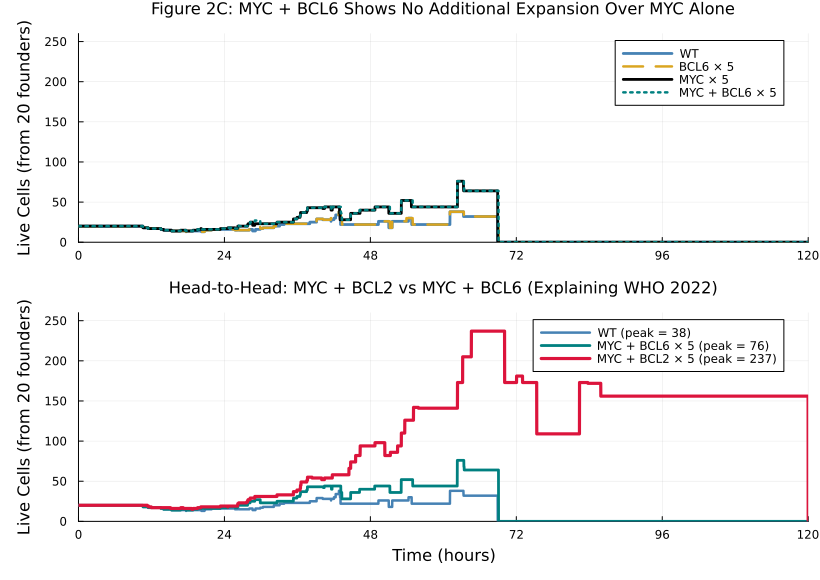

In [4]:
t_h  = pop_bcl6["WT"].t_hours
wt   = pop_bcl6["WT"].total
myc  = pop_bcl6["MYC × 5"].total
b6   = pop_bcl6["BCL6 × 5"].total
mb6  = pop_bcl6["MYC + BCL6 × 5"].total
mb2  = pop_myc_bcl2.total

# Panel 1: MYC + BCL6 conditions (Figure 2C)
p_c1 = plot(t_h, wt,  lw=2.8, color=:steelblue, label="WT")
plot!(p_c1, t_h, b6,  lw=2.5, color=:goldenrod, linestyle=:dash, label="BCL6 × 5")
plot!(p_c1, t_h, myc, lw=2.8, color=:black,     label="MYC × 5")
plot!(p_c1, t_h, mb6, lw=2.5, color=:teal,      linestyle=:dot,  label="MYC + BCL6 × 5")
plot!(p_c1, ylabel="Live Cells (from $(N_CELLS) founders)",
      title="Figure 2C: MYC + BCL6 Shows No Additional Expansion Over MYC Alone",
      titlefontsize=11, xlims=(0, 120), xticks=0:24:120, ylims=(0, 260), legend=:topright)

# Panel 2: Direct head-to-head comparison of the two Double Hits
p_c2 = plot(t_h, wt,  lw=2.5, color=:steelblue, label="WT (peak = $(round(Int, maximum(wt))))")
plot!(p_c2, t_h, mb6, lw=2.8, color=:teal,      label="MYC + BCL6 × 5 (peak = $(round(Int, maximum(mb6))))")
plot!(p_c2, t_h, mb2, lw=3.2, color=:crimson,   label="MYC + BCL2 × 5 (peak = $(round(Int, maximum(mb2))))")
plot!(p_c2, xlabel="Time (hours)", ylabel="Live Cells (from $(N_CELLS) founders)",
      title="Head-to-Head: MYC + BCL2 vs MYC + BCL6 (Explaining WHO 2022)",
      titlefontsize=11, xlims=(0, 120), xticks=0:24:120, ylims=(0, 260), legend=:topright)

plot(p_c1, p_c2, layout=(2, 1), size=(820, 580), left_margin=4Plots.mm)

---

## Step 3: Look Inside the Cell — Why Didn't BCL6 Cause Synergy?

Did `BCL6 × 5` fail to work inside the model, or did it act on a **different biological axis**?

Let's inspect the **Differentiation module** (`Bcl6` and `Blimp1`) inside a single stimulated cell for `WT` vs `BCL6 × 5`. You will see that `BCL6 × 5` strongly elevates **BCL6 protein** and **represses Blimp1 by more than 5-fold** — locking the cell out of terminal plasma-cell differentiation. However, because **BCL6 does not directly inhibit mitochondrial MOMP**, apoptosis still terminates the cell at the same time (~26.3 h), preventing the exponential survival × proliferation synergy seen with **MYC + BCL2**!

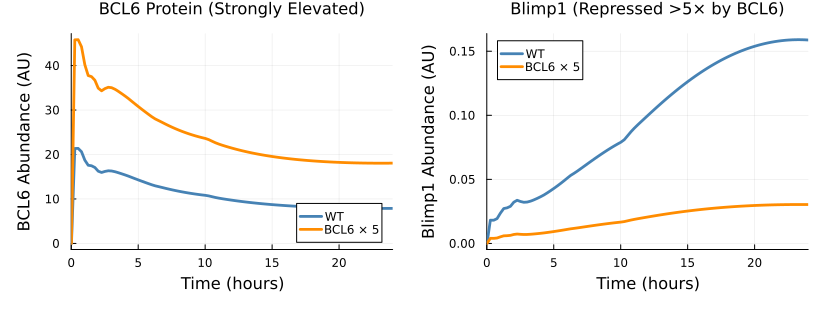

In [5]:
function trace_diff_module(mods::Dict{String, Float64})
    p = copy(base_p)
    for (k, v) in mods
        p[findfirst(==(k), parameterNameList)] *= v
    end
    y0 = copy(base_y0)
    y0[idx_Bcl2t]  = 277.0
    y0[idx_Ligand] = 0.0
    ss = solve(ODEProblem(f_ss, y0, (0.0, 1440.0), p), ms_alg;
               callback=cbs_ss, abstol=1e-5, reltol=1e-3, save_everystep=false)
    u = copy(ss.u[end])
    u[idx_Cdh1] = 1.0; u[idx_IRF4] = 0.0; u[idx_AID] = 0.0
    u[idx_Blimp1] = 0.0; u[idx_Pax5] = 1.0; u[idx_Bcl6] = 0.0; u[idx_Ligand] = 1.0
    p[idx_NIKdeg] /= 10.0

    sol = solve(ODEProblem(f_tc, u, (1.0, 1500.0), p), ms_alg;
                callback=cbs_tc, abstol=1e-5, reltol=1e-3, saveat=15.0)
    return (
        t_h    = sol.t ./ 60.0,
        bcl6   = [x[idx_Bcl6]   for x in sol.u],
        blimp1 = [x[idx_Blimp1] for x in sol.u],
    )
end

d_wt = trace_diff_module(Dict{String, Float64}())
d_b6 = trace_diff_module(Dict("k1_s_Bcl6-differentiation" => 5.0))

p_bcl6 = plot(d_wt.t_h, d_wt.bcl6, lw=2.8, color=:steelblue, label="WT")
plot!(p_bcl6, d_b6.t_h, d_b6.bcl6, lw=2.8, color=:darkorange, label="BCL6 × 5")
plot!(p_bcl6, xlabel="Time (hours)", ylabel="BCL6 Abundance (AU)",
      title="BCL6 Protein (Strongly Elevated)", titlefontsize=11, xlims=(0, 24), legend=:bottomright)

p_blimp = plot(d_wt.t_h, d_wt.blimp1, lw=2.8, color=:steelblue, label="WT")
plot!(p_blimp, d_b6.t_h, d_b6.blimp1, lw=2.8, color=:darkorange, label="BCL6 × 5")
plot!(p_blimp, xlabel="Time (hours)", ylabel="Blimp1 Abundance (AU)",
      title="Blimp1 (Repressed >5× by BCL6)", titlefontsize=11, xlims=(0, 24), legend=:topleft)

plot(p_bcl6, p_blimp, layout=(1, 2), size=(820, 320), left_margin=4Plots.mm, bottom_margin=4Plots.mm)

---

## Interactive Exercise: Generalising the Double-Hit Principle (Norris *et al.* Figure 2E — Gain1q)

A key takeaway of *Norris et al.* (2024) is that **synergy is a systems-level property, not unique to the exact genes *MYC* and *BCL2***. For example, in **Multiple Myeloma** with **chromosome 1q amplification (`gain1q`, Figure 2E)**, two co-amplified genes on chromosome 1q act on the exact same two axes:
- **`MCL1`** (anti-apoptotic, modelled via `"k1_bcl2Exp-linking"`) protects mitochondria from apoptosis (**AA**).
- **`CKS1B`** accelerates degradation of the cell-cycle brake **p27** (modelled by lowering `"k2_5-cellCycle"`, e.g. `0.5×`, or boosting `"k3_7-cellCycle"` Cyclin E, **PP**).

**Your task:** Test whether combining a **non-MYC cell-cycle hit** (`"k2_5-cellCycle" => 0.5`, p27 loss / CKS1B gain) with an **anti-apoptotic hit** (`"k1_bcl2Exp-linking" => 5.0`, BCL2/MCL1 gain) reproduces super-additive synergy in `N_EX = 10` founder cells!

Row,Condition,Peak_Cells
,String,Int64
1,WT,38
2,p27 loss (0.5×),64
3,BCL2 / MCL1 (5×),111
4,p27 loss (0.5×) + BCL2 / MCL1 (5×),193


Peak super-additive synergy: +146.0 extra cells above additive prediction!


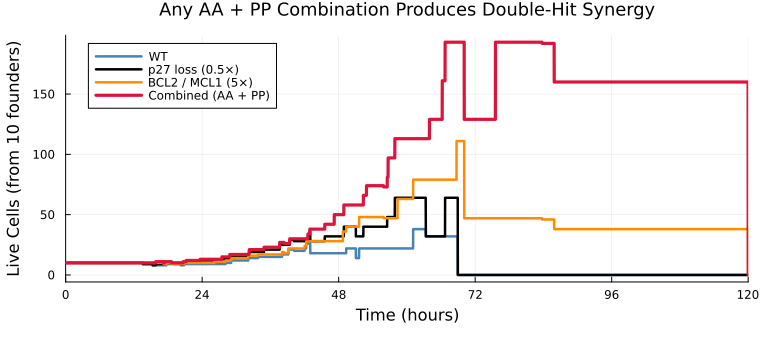

In [6]:
# Exercise: Test a non-MYC cell-cycle hit (p27 loss: "k2_5-cellCycle" => 0.5) + anti-apoptotic hit (BCL2/MCL1 × 5)!
const N_EX = 10

hit_A_name = "p27 loss (0.5×)"
hit_A_mods = Dict("k2_5-cellCycle" => 0.5)

hit_B_name = "BCL2 / MCL1 (5×)"
hit_B_mods = Dict("k1_bcl2Exp-linking" => 5.0)

combo_mods = merge(hit_A_mods, hit_B_mods)

p_wt_e = run_population(Dict{String, Float64}(), N_EX; preCV=0.11, seed=123)
p_a_e  = run_population(hit_A_mods, N_EX; preCV=0.11, seed=123)
p_b_e  = run_population(hit_B_mods, N_EX; preCV=0.11, seed=123)
p_ab_e = run_population(combo_mods, N_EX; preCV=0.11, seed=123)

obs_e = p_ab_e.total .- p_wt_e.total
add_e = (p_a_e.total .- p_wt_e.total) .+ (p_b_e.total .- p_wt_e.total)
syn_e = obs_e .- add_e

display(DataFrame(
    Condition  = ["WT", hit_A_name, hit_B_name, "$(hit_A_name) + $(hit_B_name)"],
    Peak_Cells = round.(Int, [maximum(p_wt_e.total), maximum(p_a_e.total), maximum(p_b_e.total), maximum(p_ab_e.total)]),
))
println("Peak super-additive synergy: +", round(maximum(syn_e), digits=1), " extra cells above additive prediction!")

p_g1q = plot(p_wt_e.t_hours, p_wt_e.total, lw=2.5, color=:steelblue, label="WT")
plot!(p_g1q, p_a_e.t_hours,  p_a_e.total,  lw=2.5, color=:black,     label=hit_A_name)
plot!(p_g1q, p_b_e.t_hours,  p_b_e.total,  lw=2.5, color=:darkorange,label=hit_B_name)
plot!(p_g1q, p_ab_e.t_hours, p_ab_e.total, lw=3.2, color=:crimson,   label="Combined (AA + PP)")
plot!(p_g1q, xlabel="Time (hours)", ylabel="Live Cells (from $(N_EX) founders)",
      title="Any AA + PP Combination Produces Double-Hit Synergy", titlefontsize=12,
      xlims=(0, 120), xticks=0:24:120, size=(760, 340))
p_g1q

````{admonition} Hint
:class: dropdown tip

Try swapping `hit_A_mods` to another pro-proliferative alteration from the cell cycle module — such as `"k3_7-cellCycle" => 2.0` (Cyclin E / *CCNE1* amplification) or `"k1_26-cellCycle" => 0.5` (*RB1* heterozygous loss) — and check whether combining it with `hit_B_mods` (`"k1_bcl2Exp-linking" => 5.0`) still creates super-additive expansion!
````

````{admonition} Reveal Solution
:class: dropdown note

```julia
p_rb1   = run_population(Dict("k1_26-cellCycle" => 0.5), 10; preCV=0.11, seed=123)
p_rb1b2 = run_population(Dict("k1_26-cellCycle" => 0.5, "k1_bcl2Exp-linking" => 5.0), 10; preCV=0.11, seed=123)
println("WT peak=", round(Int, maximum(p_wt_e.total)),
        ", RB1-loss peak=", round(Int, maximum(p_rb1.total)),
        ", BCL2x5 peak=", round(Int, maximum(p_b_e.total)),
        ", RB1-loss + BCL2x5 peak=", round(Int, maximum(p_rb1b2.total)))
```

Whenever mutations simultaneously drive **pro-proliferative (PP)** cell-cycle signalling *and* **anti-apoptotic (AA)** survival signalling, the multiscale model predicts aggressive, super-additive tumour expansion — even when neither *MYC* nor *BCL2* itself is translocated!
````

---

## Summary & Looking Ahead to Patient-Specific Modelling

In Tutorial 6, you built and ran the full **193-species agent-based multiscale B-cell model**:
- **Chapter 1:** Wired five separate CSV modules (`NFkB`, `cellCycle`, `apoptosis`, `differentiation`, `linking`) together and saw how `ContinuousCallback` tripwires drive single-cell division and death.
- **Chapter 2:** Simulated heterogeneous populations (`preCV = 0.11`) and recreated **Figure 2B** of *Norris et al.*, demonstrating strong super-additive synergy in **MYC + BCL2** Double-Hit Lymphoma.
- **Chapter 3:** Recreated **Figure 2C**, explaining why **MYC + BCL6** does not generate the same cell-count synergy (matching the WHO 2022 clinical reclassification), and saw that *any* **AA + PP** mutation pair can generate double-hit-like behaviour.

:::{tip} Next Up (Tutorial 7 — Patient-Specific Lymphoma Modelling)
Real DLBCL patients rarely carry just one or two clean textbook translocations — they carry complex combinations of 3–15 mutations and copy-number changes. In **Tutorial 7**, we map real patient genomic sequencing data directly into this 193-species model, extract 6-hour **AA** and **PP** biomarkers, and predict **10-year clinical survival** across hundreds of DLBCL patients!
:::